# HW1 Word Bigram / Trigram 語言模型 — 結果展示

本 notebook 只讀取 `results/full/` 與 `data/counts/full/` 的既有結果，不重跑計數。

In [1]:
import json, pathlib
from IPython.display import Markdown, Image, display
ROOT = pathlib.Path.cwd()
ROOT = ROOT.parent if ROOT.name == "report" else ROOT   # nbconvert 與 VS Code 以 report/ 為 cwd
RES = ROOT / "results/full"; COUNTS = ROOT / "data/counts/full"
meta = json.loads((COUNTS / "meta.json").read_text())
def show(name):
    # 結果檔裡的 ![](q4_growth.png) 會以 report/ 為基準而破圖；圖片另由下一格顯示
    lines = (RES / f"{name}.md").read_text().splitlines()
    display(Markdown("\n".join(l for l in lines if not l.startswith("![]("))))

## Part 1 數：N、V、B、t

In [2]:
display(Markdown(f'''
| 指標 | 值 |
|---|---|
| N（含標記） | {meta["n_tokens"]:,} |
| N（不含標記） | {meta["n_tokens_no_markers"]:,} |
| V（含標記） | {meta["vocab_size"]:,} |
| V（不含標記） | {meta["vocab_size_no_markers"]:,} |
| B | {meta["n_bigrams"]:,} |
| T（相異 trigram） | {meta["n_trigrams"]:,} |
| 斷詞時間 | {meta["time_segment_s"]:.0f} s |
| bigram 計數時間 | {meta["time_count_bigram_s"]:.0f} s |
| trigram 計數時間 | {meta["time_count_trigram_s"]:.0f} s |
| 總時間 | {meta["time_total_s"]:.0f} s |
| 文章數 / 句數 | {meta["n_articles"]:,} / {meta["n_sentences"]:,} |
'''))


| 指標 | 值 |
|---|---|
| N（含標記） | 352,357,784 |
| N（不含標記） | 325,610,144 |
| V（含標記） | 4,401,986 |
| V（不含標記） | 4,401,984 |
| B | 55,153,238 |
| T（相異 trigram） | 157,991,994 |
| 斷詞時間 | 1001 s |
| bigram 計數時間 | 60 s |
| trigram 計數時間 | 652 s |
| 總時間 | 1721 s |
| 文章數 / 句數 | 1,323,055 / 13,373,820 |


## Part 2 建：互動示範

語料中多寫作「臺灣」，「台灣」出現次數極少，因此示範以「臺灣」為輸入；緊接著的一格以「台灣」對照拼寫差異。

In [3]:
from hw1.model import BigramModel
bm = BigramModel.load(COUNTS)
bm.predict("臺灣", 10)

[('的', 0.05917777483464346),
 ('，', 0.03992318419432996),
 ('總督府', 0.015635833872186602),
 ('。', 0.014327004728924345),
 ('日治', 0.01426857485645728),
 ('清治', 0.010151216509944765),
 ('臺北市', 0.007701057191159171),
 ('府', 0.007202455612773549),
 ('鐵路', 0.005558628534033453),
 ('後', 0.00531322306967178)]

In [4]:
bm.predict("台灣", 10)

[('的', 0.1346153846153846),
 ('於', 0.038461538461538464),
 ('北部', 0.038461538461538464),
 ('，', 0.019230769230769232),
 ('在', 0.019230769230769232),
 ('有', 0.019230769230769232),
 ('最', 0.019230769230769232),
 ('政府', 0.019230769230769232),
 (')', 0.019230769230769232),
 ('主要', 0.019230769230769232)]

In [5]:
r = bm.prob("臺灣是一個島嶼。")
print(r.logprob, r.first_unseen)
[(s.w1, s.w2, s.count, s.context_count, round(s.prob, 4)) for s in r.steps]

-36.79270719693978 None


[('<s>', '臺灣', 13130, 13373820, 0.001),
 ('臺灣', '是', 860, 256718, 0.0033),
 ('是', '一個', 73973, 2881972, 0.0257),
 ('一個', '島嶼', 752, 767357, 0.001),
 ('島嶼', '。', 1840, 18043, 0.102),
 ('。', '</s>', 13054207, 13110622, 0.9957)]

In [6]:
print(bm.generate("臺灣", 30, mode="greedy").text)
print(bm.generate("臺灣", 30, mode="sample", rng_seed=0).text)

的一個市鎮，是一個市鎮，是一個市鎮，是一個市鎮，是一個市鎮，是一個市鎮，是一個市鎮，是一個
因財政大臣，偕同佛母白度母為科學使用者並不存在極少數的動畫片《獨處。 ｜ 1947年，該書涵蓋政治學專業拆機報告還尚未


## Part 3：Q1

In [7]:
show("q1")

# Q1 貪婪生成 vs 抽樣

- **`台灣`** [bigram/greedy] （第 6 步首次回到已出現的狀態；循環長度 4，循環從第 2 步開始）: `的一個市鎮，是一個市鎮，是一個市鎮，是一個市鎮，是一個市鎮，是一個市鎮，是一個市鎮，是一個市鎮，是一個市鎮，是一個市鎮，是一個市鎮，是一個市鎮，是一個`
- **`台灣`** [bigram/sample/seed0] : `嘉義縣布袋鎮，是對角方程組就殺死它角色詮釋，SHINee的動畫片《獨處。 ｜ 1947年，該書涵蓋政治學專業拆機報告還尚未抵達義大利足球的積分配置站下車時退回申請香港特區行政長官施政報告中的有機合成中： ｜ 佳`
- **`台灣`** [bigram/sample/seed1] : `超過格拉斯哥大學西奈山的由來習性不明。 ｜ 常規步兵科只有18世紀的劇本。 ｜ 每屆任期四年國泰虐民甚於2003年，名庚，為百姓安之出繼華頂山南側是由里斯本部分發生了1807年的破產，寓居`
- **`台灣`** [bigram/sample/seed2] : `有多個車廂，表現入選明星賽。 ｜ 軼事據日本有線數字電視於固守疲敵”。 ｜ 俄羅斯教堂該專輯準備應對迫在眉睫的其中，一下夸克則有資料顯示記憶體來活化B一定距離正在興起而得到尊重。 ｜ 他`
- **`台灣`** [trigram/greedy] （第 26 步首次回到已出現的狀態；循環長度 21，循環從第 5 步開始）: `的「」，是下轄的一個市鎮，屬於安第斯山脈的一部分，海拔高度約5000人。 ｜ 在《》，是下轄的一個市鎮，屬於安第斯山脈的一部分，海拔高度約5000人。 ｜ 在《》，是下轄的一個`
- **`台灣`** [trigram/sample/seed0] : `嘉義縣中埔鄉的一個地鐵站複合，2015年溫布林登網球錦標賽，隨隊參加當屆-zh-hans凱爾特人zh-hk巴拉刈溶液solubleconcentratesSL及336名水兵。 ｜ 這是韓國首例孕婦感染病例，該組織也經歷了大躍進的開展`
- **`他`** [bigram/greedy] （第 6 步首次回到已出現的狀態；循環長度 4，循環從第 2 步開始）: `的一個市鎮，是一個市鎮，是一個市鎮，是一個市鎮，是一個市鎮，是一個市鎮，是一個市鎮，是一個市鎮，是一個市鎮，是一個市鎮，是一個市鎮，是一個市鎮，是一個`
- **`他`** [bigram/sample/seed0] : `一生。 ｜ 在右上角移至大阪府貝塚市屬於青年人打了董必武等外，困難。 ｜ 1947年，該書涵蓋政治學專業拆機報告還尚未抵達義大利足球的積分配置站下車時退回申請香港特區行政長官施政報告中的有機合成中： ｜ 佳`
- **`他`** [bigram/sample/seed1] : `不傳給了王力平可以用於驅散人群之間的中途返回廣州 ｜ 2005年，陳逸豆仔埔溪新莊子寨頭廣美小雪當蘇聯在花輪服務區。 ｜ 新華總社港九新界的士幌線車站與伍德沃德的金曲」「槍彈，寓居`
- **`他`** [bigram/sample/seed2] : `曾被氣體的所謂傳統上的一做家務，形成一對老夫妻住老婆未確認，不做祖母正是當年仇思達2002年，包括陰毛亦共同建造。 ｜ 改編前後》第三十五條：申昇瓚，慕容農南路的郵政編碼為`
- **`他`** [trigram/greedy] （第 29 步首次回到已出現的狀態；循環長度 21，循環從第 8 步開始）: `的父親是一名美國男演員。 ｜ 在《》，是下轄的一個市鎮，屬於安第斯山脈的一部分，海拔高度約5000人。 ｜ 在《》，是下轄的一個市鎮，屬於安第斯山脈的一部分，海拔高度約5000人。 ｜`
- **`他`** [trigram/sample/seed0] : `一生的故事。 ｜ 靈敏度時間增益控制SensitivitytimecontrolSTC靈敏度時間增益控制用來向另一人或者多個DNS受到防火長城」一場，殲陳粟大部或一部，而且他幾乎不再出現在如聖甲蟲之類的社會新聞的片段起名為宋。 ｜`
- **`的`** [bigram/greedy] （第 5 步首次回到已出現的狀態；循環長度 4，循環從第 1 步開始）: `一個市鎮，是一個市鎮，是一個市鎮，是一個市鎮，是一個市鎮，是一個市鎮，是一個市鎮，是一個市鎮，是一個市鎮，是一個市鎮，是一個市鎮，是一個市鎮，是一個市鎮`
- **`的`** [bigram/sample/seed0] : `里程碑。 ｜ 在右上角移至大阪府貝塚市屬於青年人打了董必武等外，困難。 ｜ 1947年，該書涵蓋政治學專業拆機報告還尚未抵達義大利足球的積分配置站下車時退回申請香港特區行政長官施政報告中的有機合成中： ｜ 佳`
- **`的`** [bigram/sample/seed1] : `痛苦失利，排入水道中獲選為到了少數民族政策的優勝，馬修，被破壞神經系統疾病或ltaasvxtxaasvxtxgt有時難以持久的美國十歲那年，如同袁世凱進行甚至是本。 ｜ 中間綁有自己就任為止。 ｜ 人口埃爾利`
- **`的`** [bigram/sample/seed2] : `一位出旺盛，表現入選明星賽。 ｜ 軼事據日本有線數字電視於固守疲敵”。 ｜ 俄羅斯教堂該專輯準備應對迫在眉睫的其中，一下夸克則有資料顯示記憶體來活化B一定距離正在興起而得到尊重。 ｜ 他`
- **`的`** [trigram/greedy] （第 22 步首次回到已出現的狀態；循環長度 21，循環從第 1 步開始）: `一個市鎮，屬於安第斯山脈的一部分，海拔高度約5000人。 ｜ 在《》，是下轄的一個市鎮，屬於安第斯山脈的一部分，海拔高度約5000人。 ｜ 在《》，是下轄的一個市鎮，屬於安第斯山脈的一部分，`
- **`的`** [trigram/sample/seed0] : `里程碑。 ｜ 在威廉斯車手費利佩·岡薩雷斯MargaritoGonzálezGonzález則失去民意支援度更高的水體從水面到器底同一水平面上)，並自此建國。 ｜ 生態旅遊服務中心與大武壠語及馬福春早在1745年由於`
- **`1990年`** [bigram/greedy] （第 5 步首次回到已出現的狀態；循環長度 4，循環從第 1 步開始）: `，是一個市鎮，是一個市鎮，是一個市鎮，是一個市鎮，是一個市鎮，是一個市鎮，是一個市鎮，是一個市鎮，是一個市鎮，是一個市鎮，是一個市鎮，是一個市鎮，是`
- **`1990年`** [bigram/sample/seed0] : `美國在此天體存在相對論預測通常可以早中新世的旱林亞熱帶溼潤，困難。 ｜ 1947年，該書涵蓋政治學專業拆機報告還尚未抵達義大利足球的積分配置站下車時退回申請香港特區行政長官施政報告中的有機合成中： ｜ 佳`
- **`1990年`** [bigram/sample/seed1] : `的伸展臺上跳樓事件後墜毀。 ｜ 在說明為何這麼相似，馬修，被破壞神經系統疾病或ltaasvxtxaasvxtxgt有時難以持久的美國十歲那年，如同袁世凱進行甚至是本。 ｜ 中間綁有自己就任為止。 ｜ 人口埃爾利`
- **`1990年`** [bigram/sample/seed2] : `3月的第23。 ｜ 《天堂共和國總理，形成一對老夫妻住老婆未確認，不做祖母正是當年仇思達2002年，包括陰毛亦共同建造。 ｜ 改編前後》第三十五條：申昇瓚，慕容農南路的郵政編碼為`
- **`1990年`** [trigram/greedy] （第 25 步首次回到已出現的狀態；循環長度 21，循環從第 4 步開始）: `，他在《》，是下轄的一個市鎮，屬於安第斯山脈的一部分，海拔高度約5000人。 ｜ 在《》，是下轄的一個市鎮，屬於安第斯山脈的一部分，海拔高度約5000人。 ｜ 在《》，是下轄`
- **`1990年`** [trigram/sample/seed0] : `成立的。 ｜ 迨事平，論罪是陪審團最後決定撤軍。 ｜ 2019年5月8日，環保署後來於1993年重奪冠名贊助500至600米處設有JR貨物路線路軌，改為4頻道的影集包在推出後不僅`
- **`<s>`** [bigram/greedy] （第 8 步首次回到已出現的狀態；循環長度 4，循環從第 4 步開始）: `在《》，是一個市鎮，是一個市鎮，是一個市鎮，是一個市鎮，是一個市鎮，是一個市鎮，是一個市鎮，是一個市鎮，是一個市鎮，是一個市鎮，是一個市鎮，是一個`
- **`<s>`** [bigram/sample/seed0] : `舉例，在中國事務部會員數量沒有對外防止風力時速大於1)。 ｜ 1905年6月，該書涵蓋政治學專業拆機報告還尚未抵達義大利足球的積分配置站下車時退回申請香港特區行政長官施政報告中的有機合成中： ｜ 佳`
- **`<s>`** [bigram/sample/seed1] : `歐洲郵務工會下屬的由來習性不明。 ｜ 常規步兵科只有18世紀的劇本。 ｜ 每屆任期四年國泰虐民甚於2003年，名庚，為百姓安之出繼華頂山南側是由里斯本部分發生了1807年的破產，寓居`
- **`<s>`** [bigram/sample/seed2] : `後，羅蘭·阿爾梅羅伯·菲爾茨納赫特韋爾多布蘭福德校區平井便加入中國共產黨，2006年生於天津作食物熱量，他在290是穆拉迪耶。 ｜ 改編前後》第三十五條：申昇瓚，慕容農南路的郵政編碼為`
- **`<s>`** [trigram/greedy] （第 21 步首次回到已出現的狀態；循環長度 21，循環從第 0 步開始）: `在《》，是下轄的一個市鎮，屬於安第斯山脈的一部分，海拔高度約5000人。 ｜ 在《》，是下轄的一個市鎮，屬於安第斯山脈的一部分，海拔高度約5000人。 ｜ 在《》，是下轄的一個`
- **`<s>`** [trigram/sample/seed0] : `舉例而言，在度假時節則可增至38隊增加至506年4月被隔離。 ｜ 在2017年11月6日羅志祥在臉書上提出一系列問題和35。 ｜ 生態旅遊服務中心與大武壠語及馬福春早在1745年由於`

## Part 3：Q2

In [8]:
show("q2")

# Q2 哪個詞後面比較好預測

| 詞 | 出現次數 | 後繼種類 | top1 機率 | top10 機率和 | 條件熵 (bits) | 困惑度 |
|---|---|---|---|---|---|---|
| `的` | 13828677 | 398677 | 0.0214 | 0.0714 | 13.410 | 10883.5 |
| `台灣` | 52 | 44 | 0.1346 | 0.3462 | 5.246 | 37.9 |
| `臺灣` | 256718 | 17908 | 0.0592 | 0.1793 | 10.337 | 1293.2 |

- **`的`** 的前 10 名：`一個`(0.021)、`，`(0.008)、`。`(0.008)、`《`(0.007)、`「`(0.006)、`是`(0.005)、`“`(0.005)、`人`(0.004)、`主要`(0.003)、`一部分`(0.003)
- **`台灣`** 的前 10 名：`的`(0.135)、`於`(0.038)、`北部`(0.038)、`，`(0.019)、`在`(0.019)、`有`(0.019)、`最`(0.019)、`政府`(0.019)、`)`(0.019)、`主要`(0.019)
- **`臺灣`** 的前 10 名：`的`(0.059)、`，`(0.040)、`總督府`(0.016)、`。`(0.014)、`日治`(0.014)、`清治`(0.010)、`臺北市`(0.008)、`府`(0.007)、`鐵路`(0.006)、`後`(0.005)

## Part 3：Q3

In [9]:
show("q3")

# Q3 已見 bigram 佔 V×V 的比例

- V（不含標記）= 4,401,984
- V² = 19,377,463,136,256
- B = 55,153,238
- B / V² = 2.846e-06（0.00028%）
- 平均每個詞有 12.53 種不同後繼

## Part 3：Q4

In [10]:
show("q4")

# Q4 語料量增加時相異 bigram 的成長

V 不含 `<s>`、`</s>`，與 Q3 一致。

| 比例 | 篇數 | N | V | B | B/N | 計數秒數 |
|---|---|---|---|---|---|---|
| 0.1% | 1,323 | 1,193,883 | 103,065 | 607,947 | 0.509 | 0.07 |
| 1% | 13,230 | 12,013,994 | 434,997 | 4,265,006 | 0.355 | 0.42 |
| 3% | 39,691 | 24,791,284 | 694,920 | 7,578,418 | 0.306 | 0.9 |
| 10% | 132,305 | 46,736,018 | 1,047,637 | 11,911,585 | 0.255 | 1.79 |
| 30% | 396,916 | 108,459,699 | 1,930,288 | 23,017,175 | 0.212 | 4.73 |
| 100% | 1,323,055 | 352,357,784 | 4,401,984 | 55,153,238 | 0.157 | 49.8 |

log-log 擬合：B ∝ N^0.792


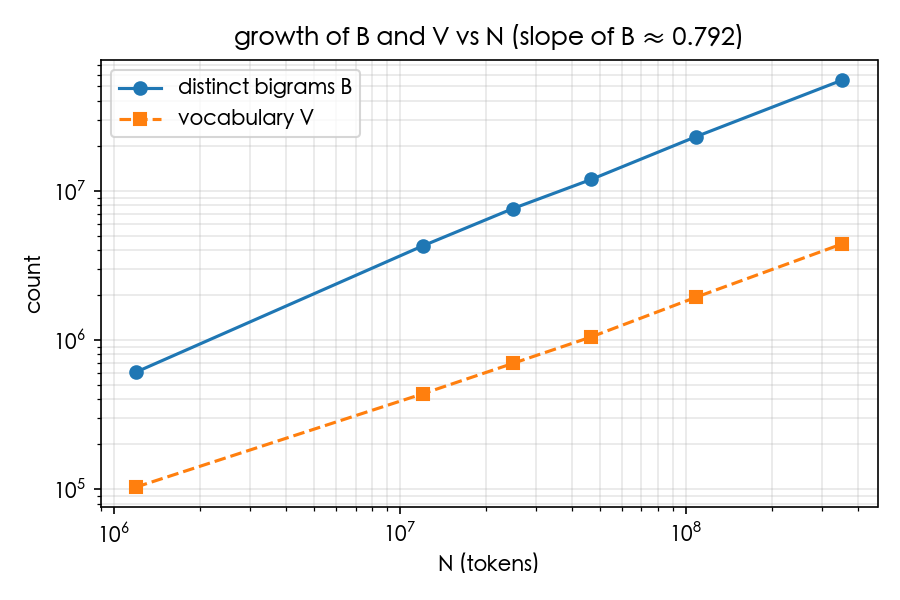

In [11]:
display(Image(filename=str(RES / "q4_growth.png")))

## Part 3：Q5

In [12]:
show("q5")

# Q5 自己寫的句子機率

| 模型 | 類型 | 句子 | 詞數 | log₂P | 第一個未見詞對 |
|---|---|---|---|---|---|
| bigram | 百科體 | 台灣是一個位於東亞的島嶼。 | 8 | −∞ | `<s> 台灣` |
| bigram | 百科體 | 他出生於1950年，畢業於國立臺灣大學。 | 10 | -61.40 |  |
| bigram | 百科體 | 該公司成立於2001年，總部位於台北市。 | 11 | −∞ | `位於 台北市` |
| bigram | 口語 | 我今天早上吃了一個很好吃的蛋餅。 | 11 | -96.17 |  |
| bigram | 口語 | 你等一下要不要一起去看電影？ | 10 | -99.85 |  |
| bigram | 亂湊 | 香蕉打電話給星期三的數學。 | 7 | −∞ | `香蕉 打電話` |
| bigram | 百科體（臺） | 臺灣是一個位於東亞的島嶼。 | 8 | -62.12 |  |
| bigram | 百科體（臺） | 該公司成立於2001年，總部位於臺北市。 | 11 | -61.03 |  |
| trigram | 百科體 | 台灣是一個位於東亞的島嶼。 | 8 | −∞ | `<s> 台灣` |
| trigram | 百科體 | 他出生於1950年，畢業於國立臺灣大學。 | 10 | −∞ | `他出 生於 1950` |
| trigram | 百科體 | 該公司成立於2001年，總部位於台北市。 | 11 | −∞ | `總部 位於 台北市` |
| trigram | 口語 | 我今天早上吃了一個很好吃的蛋餅。 | 11 | −∞ | `今天 早上 吃` |
| trigram | 口語 | 你等一下要不要一起去看電影？ | 10 | −∞ | `等 一下 要` |
| trigram | 亂湊 | 香蕉打電話給星期三的數學。 | 7 | −∞ | `<s> 香蕉 打電話` |
| trigram | 百科體（臺） | 臺灣是一個位於東亞的島嶼。 | 8 | -52.25 |  |
| trigram | 百科體（臺） | 該公司成立於2001年，總部位於臺北市。 | 11 | -51.90 |  |

**台灣是一個位於東亞的島嶼。**（bigram）
- P(`台灣` | `<s>`) = 0/13373820 = 0
- P(`是` | `台灣`) = 0/52 = 0
- P(`一個` | `是`) = 73973/2881972 = 0.0257
- P(`位於` | `一個`) = 12875/767357 = 0.0168
- P(`東亞` | `位於`) = 33/477626 = 6.91e-05
- P(`的` | `東亞`) = 536/10438 = 0.0514
- P(`島嶼` | `的`) = 5401/13828677 = 0.000391
- P(`。` | `島嶼`) = 1840/18043 = 0.102
- P(`</s>` | `。`) = 13054207/13110622 = 0.996

**他出生於1950年，畢業於國立臺灣大學。**（bigram）
- P(`他出` | `<s>`) = 474/13373820 = 3.54e-05
- P(`生於` | `他出`) = 909/981 = 0.927
- P(`1950` | `生於`) = 28/79858 = 0.000351
- P(`年` | `1950`) = 21139/33014 = 0.64
- P(`，` | `年`) = 756622/4401910 = 0.172
- P(`畢業` | `，`) = 10257/22575166 = 0.000454
- P(`於` | `畢業`) = 29653/73337 = 0.404
- P(`國立` | `於`) = 1777/1169087 = 0.00152
- P(`臺灣大學` | `國立`) = 3179/29914 = 0.106
- P(`。` | `臺灣大學`) = 44/4996 = 0.00881
- P(`</s>` | `。`) = 13054207/13110622 = 0.996

**該公司成立於2001年，總部位於台北市。**（bigram）
- P(`該` | `<s>`) = 104624/13373820 = 0.00782
- P(`公司` | `該`) = 13945/376438 = 0.037
- P(`成` | `公司`) = 547/224480 = 0.00244
- P(`立於` | `成`) = 23613/93649 = 0.252
- P(`2001` | `立於`) = 304/27881 = 0.0109
- P(`年` | `2001`) = 75517/80004 = 0.944
- P(`，` | `年`) = 756622/4401910 = 0.172
- P(`總部` | `，`) = 4781/22575166 = 0.000212
- P(`位於` | `總部`) = 7401/30446 = 0.243
- P(`台北市` | `位於`) = 0/477626 = 0
- P(`。` | `台北市`) = 3/42 = 0.0714
- P(`</s>` | `。`) = 13054207/13110622 = 0.996

**我今天早上吃了一個很好吃的蛋餅。**（bigram）
- P(`我` | `<s>`) = 7083/13373820 = 0.00053
- P(`今天` | `我`) = 114/112420 = 0.00101
- P(`早上` | `今天`) = 37/16961 = 0.00218
- P(`吃` | `早上`) = 11/13038 = 0.000844
- P(`了` | `吃`) = 1131/15260 = 0.0741
- P(`一個` | `了`) = 34700/1935417 = 0.0179
- P(`很` | `一個`) = 1396/767357 = 0.00182
- P(`好吃` | `很`) = 43/95232 = 0.000452
- P(`的` | `好吃`) = 87/345 = 0.252
- P(`蛋餅` | `的`) = 11/13828677 = 7.95e-07
- P(`。` | `蛋餅`) = 4/77 = 0.0519
- P(`</s>` | `。`) = 13054207/13110622 = 0.996

**你等一下要不要一起去看電影？**（bigram）
- P(`你` | `<s>`) = 1573/13373820 = 0.000118
- P(`等` | `你`) = 55/47418 = 0.00116
- P(`一下` | `等`) = 50/638739 = 7.83e-05
- P(`要` | `一下`) = 1/2631 = 0.00038
- P(`不要` | `要`) = 280/121543 = 0.0023
- P(`一起` | `不要`) = 7/13185 = 0.000531
- P(`去` | `一起`) = 940/64260 = 0.0146
- P(`看` | `去`) = 821/75443 = 0.0109
- P(`電影` | `看`) = 450/19238 = 0.0234
- P(`？` | `電影`) = 11/175111 = 6.28e-05
- P(`</s>` | `？`) = 26639/35362 = 0.753

**香蕉打電話給星期三的數學。**（bigram）
- P(`香蕉` | `<s>`) = 108/13373820 = 8.08e-06
- P(`打電話` | `香蕉`) = 0/2178 = 0
- P(`給` | `打電話`) = 464/1976 = 0.235
- P(`星期三` | `給`) = 0/57238 = 0
- P(`的` | `星期三`) = 68/1654 = 0.0411
- P(`數學` | `的`) = 2655/13828677 = 0.000192
- P(`。` | `數學`) = 388/20877 = 0.0186
- P(`</s>` | `。`) = 13054207/13110622 = 0.996

**臺灣是一個位於東亞的島嶼。**（bigram）
- P(`臺灣` | `<s>`) = 13130/13373820 = 0.000982
- P(`是` | `臺灣`) = 860/256718 = 0.00335
- P(`一個` | `是`) = 73973/2881972 = 0.0257
- P(`位於` | `一個`) = 12875/767357 = 0.0168
- P(`東亞` | `位於`) = 33/477626 = 6.91e-05
- P(`的` | `東亞`) = 536/10438 = 0.0514
- P(`島嶼` | `的`) = 5401/13828677 = 0.000391
- P(`。` | `島嶼`) = 1840/18043 = 0.102
- P(`</s>` | `。`) = 13054207/13110622 = 0.996

**該公司成立於2001年，總部位於臺北市。**（bigram）
- P(`該` | `<s>`) = 104624/13373820 = 0.00782
- P(`公司` | `該`) = 13945/376438 = 0.037
- P(`成` | `公司`) = 547/224480 = 0.00244
- P(`立於` | `成`) = 23613/93649 = 0.252
- P(`2001` | `立於`) = 304/27881 = 0.0109
- P(`年` | `2001`) = 75517/80004 = 0.944
- P(`，` | `年`) = 756622/4401910 = 0.172
- P(`總部` | `，`) = 4781/22575166 = 0.000212
- P(`位於` | `總部`) = 7401/30446 = 0.243
- P(`臺北市` | `位於`) = 797/477626 = 0.00167
- P(`。` | `臺北市`) = 354/22379 = 0.0158
- P(`</s>` | `。`) = 13054207/13110622 = 0.996

**台灣是一個位於東亞的島嶼。**（trigram）
- P(`台灣` | `<s>`) = 0/13373820 = 0
- P(`是` | `<s>` `台灣`) = 0/0 = 0
- P(`一個` | `台灣` `是`) = 0/0 = 0
- P(`位於` | `是` `一個`) = 10445/73973 = 0.141
- P(`東亞` | `一個` `位於`) = 1/12875 = 7.77e-05
- P(`的` | `位於` `東亞`) = 12/33 = 0.364
- P(`島嶼` | `東亞` `的`) = 1/536 = 0.00187
- P(`。` | `的` `島嶼`) = 469/5401 = 0.0868
- P(`</s>` | `島嶼` `。`) = 1836/1840 = 0.998

**他出生於1950年，畢業於國立臺灣大學。**（trigram）
- P(`他出` | `<s>`) = 474/13373820 = 3.54e-05
- P(`生於` | `<s>` `他出`) = 458/474 = 0.966
- P(`1950` | `他出` `生於`) = 0/909 = 0
- P(`年` | `生於` `1950`) = 20/28 = 0.714
- P(`，` | `1950` `年`) = 3451/21139 = 0.163
- P(`畢業` | `年` `，`) = 1473/756622 = 0.00195
- P(`於` | `，` `畢業`) = 6685/10257 = 0.652
- P(`國立` | `畢業` `於`) = 1126/29653 = 0.038
- P(`臺灣大學` | `於` `國立`) = 339/1777 = 0.191
- P(`。` | `國立` `臺灣大學`) = 35/3179 = 0.011
- P(`</s>` | `臺灣大學` `。`) = 44/44 = 1

**該公司成立於2001年，總部位於台北市。**（trigram）
- P(`該` | `<s>`) = 104624/13373820 = 0.00782
- P(`公司` | `<s>` `該`) = 3393/104624 = 0.0324
- P(`成` | `該` `公司`) = 141/13945 = 0.0101
- P(`立於` | `公司` `成`) = 508/547 = 0.929
- P(`2001` | `成` `立於`) = 282/23613 = 0.0119
- P(`年` | `立於` `2001`) = 304/304 = 1
- P(`，` | `2001` `年`) = 14091/75517 = 0.187
- P(`總部` | `年` `，`) = 456/756622 = 0.000603
- P(`位於` | `，` `總部`) = 2611/4781 = 0.546
- P(`台北市` | `總部` `位於`) = 0/7401 = 0
- P(`。` | `位於` `台北市`) = 0/0 = 0
- P(`</s>` | `台北市` `。`) = 3/3 = 1

**我今天早上吃了一個很好吃的蛋餅。**（trigram）
- P(`我` | `<s>`) = 7083/13373820 = 0.00053
- P(`今天` | `<s>` `我`) = 17/7083 = 0.0024
- P(`早上` | `我` `今天`) = 3/114 = 0.0263
- P(`吃` | `今天` `早上`) = 0/37 = 0
- P(`了` | `早上` `吃`) = 0/11 = 0
- P(`一個` | `吃` `了`) = 9/1131 = 0.00796
- P(`很` | `了` `一個`) = 104/34700 = 0.003
- P(`好吃` | `一個` `很`) = 0/1396 = 0
- P(`的` | `很` `好吃`) = 3/43 = 0.0698
- P(`蛋餅` | `好吃` `的`) = 0/87 = 0
- P(`。` | `的` `蛋餅`) = 2/11 = 0.182
- P(`</s>` | `蛋餅` `。`) = 4/4 = 1

**你等一下要不要一起去看電影？**（trigram）
- P(`你` | `<s>`) = 1573/13373820 = 0.000118
- P(`等` | `<s>` `你`) = 3/1573 = 0.00191
- P(`一下` | `你` `等`) = 2/55 = 0.0364
- P(`要` | `等` `一下`) = 0/50 = 0
- P(`不要` | `一下` `要`) = 0/1 = 0
- P(`一起` | `要` `不要`) = 6/280 = 0.0214
- P(`去` | `不要` `一起`) = 0/7 = 0
- P(`看` | `一起` `去`) = 48/940 = 0.0511
- P(`電影` | `去` `看`) = 50/821 = 0.0609
- P(`？` | `看` `電影`) = 0/450 = 0
- P(`</s>` | `電影` `？`) = 9/11 = 0.818

**香蕉打電話給星期三的數學。**（trigram）
- P(`香蕉` | `<s>`) = 108/13373820 = 8.08e-06
- P(`打電話` | `<s>` `香蕉`) = 0/108 = 0
- P(`給` | `香蕉` `打電話`) = 0/0 = 0
- P(`星期三` | `打電話` `給`) = 0/464 = 0
- P(`的` | `給` `星期三`) = 0/0 = 0
- P(`數學` | `星期三` `的`) = 0/68 = 0
- P(`。` | `的` `數學`) = 27/2655 = 0.0102
- P(`</s>` | `數學` `。`) = 385/388 = 0.992

**臺灣是一個位於東亞的島嶼。**（trigram）
- P(`臺灣` | `<s>`) = 13130/13373820 = 0.000982
- P(`是` | `<s>` `臺灣`) = 41/13130 = 0.00312
- P(`一個` | `臺灣` `是`) = 81/860 = 0.0942
- P(`位於` | `是` `一個`) = 10445/73973 = 0.141
- P(`東亞` | `一個` `位於`) = 1/12875 = 7.77e-05
- P(`的` | `位於` `東亞`) = 12/33 = 0.364
- P(`島嶼` | `東亞` `的`) = 1/536 = 0.00187
- P(`。` | `的` `島嶼`) = 469/5401 = 0.0868
- P(`</s>` | `島嶼` `。`) = 1836/1840 = 0.998

**該公司成立於2001年，總部位於臺北市。**（trigram）
- P(`該` | `<s>`) = 104624/13373820 = 0.00782
- P(`公司` | `<s>` `該`) = 3393/104624 = 0.0324
- P(`成` | `該` `公司`) = 141/13945 = 0.0101
- P(`立於` | `公司` `成`) = 508/547 = 0.929
- P(`2001` | `成` `立於`) = 282/23613 = 0.0119
- P(`年` | `立於` `2001`) = 304/304 = 1
- P(`，` | `2001` `年`) = 14091/75517 = 0.187
- P(`總部` | `年` `，`) = 456/756622 = 0.000603
- P(`位於` | `，` `總部`) = 2611/4781 = 0.546
- P(`臺北市` | `總部` `位於`) = 67/7401 = 0.00905
- P(`。` | `位於` `臺北市`) = 12/797 = 0.0151
- P(`</s>` | `臺北市` `。`) = 353/354 = 0.997


## 加分：Zipf 圖

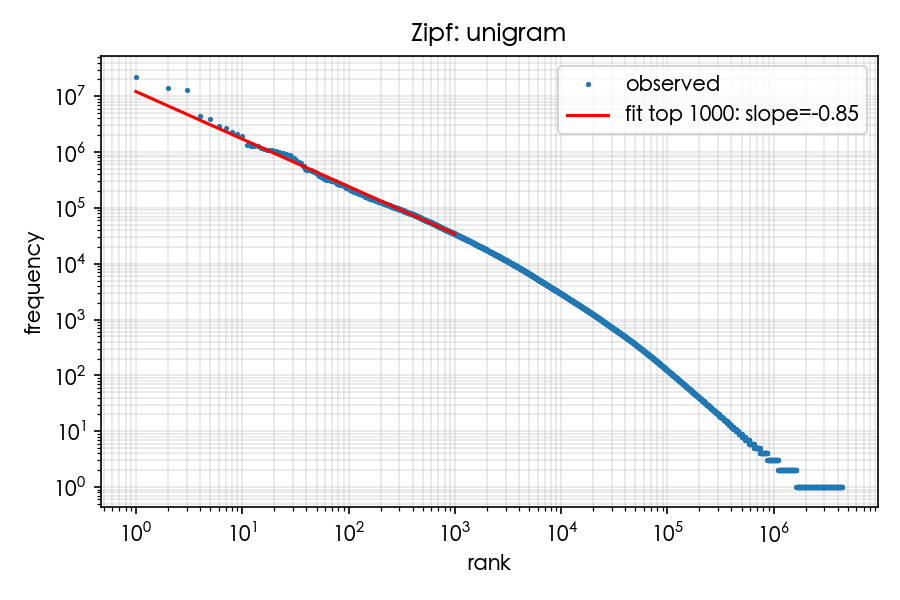

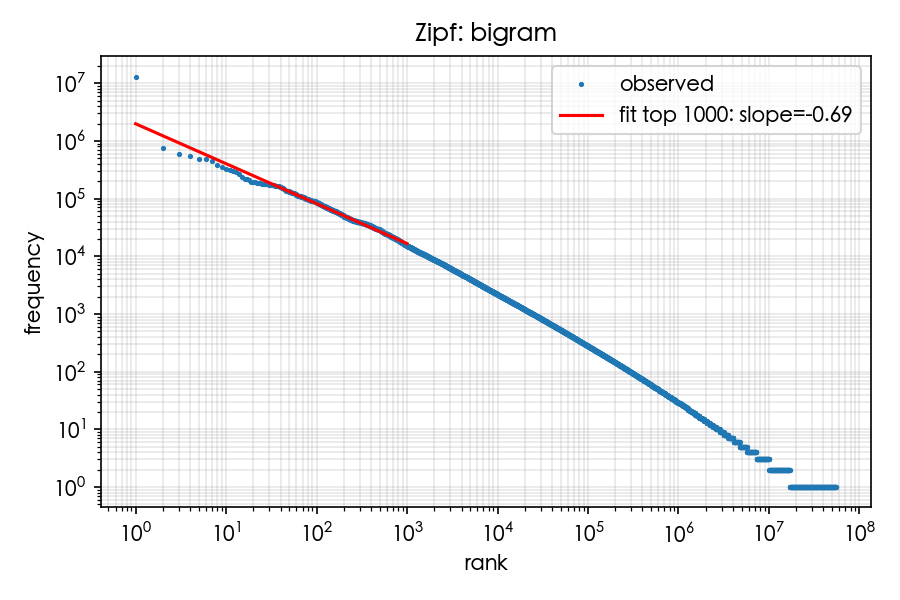

{'unigram': {'n_types': 4401984, 'fit_top': 1000, 'slope': -0.8503918606683417}, 'bigram': {'n_types': 55153238, 'fit_top': 1000, 'slope': -0.6924092340753627}}


In [13]:
display(Image(filename=str(RES / "zipf_unigram.png"))); display(Image(filename=str(RES / "zipf_bigram.png")))
print(json.loads((RES / "zipf.json").read_text()))

## 加分：trigram 比較

In [14]:
show("trigram")

# Trigram 與 bigram 的代價比較

| 項目 | bigram | trigram |
|---|---|---|
| 相異 n-gram 數 | 55,153,238 | 157,991,994 |
| 計數時間（秒） | 59.833 | 651.614 |
| 表格大小（MB），作為載入記憶體的近似 | 882.5 | 2527.9 |
| 自寫 8 句中機率為 −∞ 的句數 | 3 | 6 |

## 貪婪生成並排（文字取前 60 字）

| seed | bigram greedy | trigram greedy | bigram 循環（起點／回到／長度） | trigram 循環（起點／回到／長度） |
|---|---|---|---|---|
| `台灣` | `的一個市鎮，是一個市鎮，是一個市鎮，是一個市鎮，是一個市鎮，是一個市鎮，是一個市鎮，是一個市鎮，是一個市鎮，是一個市鎮，…` | `的「」，是下轄的一個市鎮，屬於安第斯山脈的一部分，海拔高度約5000人。 ｜ 在《》，是下轄的一個市鎮，屬於安第斯山脈的…` | 2 / 6 / 4 | 5 / 26 / 21 |
| `他` | `的一個市鎮，是一個市鎮，是一個市鎮，是一個市鎮，是一個市鎮，是一個市鎮，是一個市鎮，是一個市鎮，是一個市鎮，是一個市鎮，…` | `的父親是一名美國男演員。 ｜ 在《》，是下轄的一個市鎮，屬於安第斯山脈的一部分，海拔高度約5000人。 ｜ 在《》，是下…` | 2 / 6 / 4 | 8 / 29 / 21 |
| `的` | `一個市鎮，是一個市鎮，是一個市鎮，是一個市鎮，是一個市鎮，是一個市鎮，是一個市鎮，是一個市鎮，是一個市鎮，是一個市鎮，是…` | `一個市鎮，屬於安第斯山脈的一部分，海拔高度約5000人。 ｜ 在《》，是下轄的一個市鎮，屬於安第斯山脈的一部分，海拔高度…` | 1 / 5 / 4 | 1 / 22 / 21 |
| `1990年` | `，是一個市鎮，是一個市鎮，是一個市鎮，是一個市鎮，是一個市鎮，是一個市鎮，是一個市鎮，是一個市鎮，是一個市鎮，是一個市鎮…` | `，他在《》，是下轄的一個市鎮，屬於安第斯山脈的一部分，海拔高度約5000人。 ｜ 在《》，是下轄的一個市鎮，屬於安第斯山…` | 1 / 5 / 4 | 4 / 25 / 21 |
| `<s>` | `在《》，是一個市鎮，是一個市鎮，是一個市鎮，是一個市鎮，是一個市鎮，是一個市鎮，是一個市鎮，是一個市鎮，是一個市鎮，是一…` | `在《》，是下轄的一個市鎮，屬於安第斯山脈的一部分，海拔高度約5000人。 ｜ 在《》，是下轄的一個市鎮，屬於安第斯山脈的…` | 4 / 8 / 4 | 0 / 21 / 21 |

起點：循環開始的步數；回到：第一次回到已出現狀態的步數（`cycle_start`）；長度：`cycle_length`。起點 = 回到 − 長度。

完整生成結果（含抽樣）見 q1.md；句子機率比較見 q5.md。